# Phase 10: Prospect / New-Business Conversion Model

**Business question this phase serves:** *if we quote a segment at a given price relative to the
market, how many prospects convert?*: the new-business counterpart to Phase 9's retention model,
completing the two effects Phase 11's scenario engine needs to weigh a repricing decision against.

**Same limitation as Phase 9:** freMTPL2 has no quote-to-bind outcomes and no competitor pricing
data, so this is, for the same reasons (`docs/PROJECT_ROADMAP.md`, Phase 9), a **documented scenario
simulator**, not a model fit to
observed conversion behavior.

**On the optional empirical anchor the roadmap flagged for this phase specifically:** Kaggle's "Health
Insurance Cross Sell Prediction" dataset was considered as a real-data anchor for this curve's shape.
It was **not used**: the only copies found were unofficial third-party GitHub mirrors of Kaggle-
restricted data, and this project would rather ship a clearly-labeled, literature-cited simulation than
a real dataset of uncertain provenance.

**What this notebook does, in order:**
1. Build a conversion-probability formula: baseline, price elasticity, and a risk-based market-access
   term, each parameter's source stated, and different from Phase 9's in three ways.
2. Validate the formula's shape, including a direct, numerical comparison against Phase 9's retention
   curve: the "new business is more price-elastic than renewal" finding, quantified.
3. Apply it to **Segment X** (`BonusMalus` 51-80, Phase 8) under the same correction as Phase 9,
   so the two effects are directly comparable when Phase 11 combines them.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.prospect.conversion_model import (
    conversion_probability,
    risk_access_dampening,
    BASELINE_CONVERSION_RATE,
    CONVERSION_PRICE_ELASTICITY,
    RISK_ACCESS_SATURATION_BONUS_MALUS,
    RISK_ACCESS_MAX_DAMPENING,
)
from src.retention.renewal_model import renewal_probability, PRICE_ELASTICITY as RETENTION_PRICE_ELASTICITY, derive_tenure_proxy

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "policy_level_clean.parquet")
print(f"Portfolio: {len(df):,} policies")

Portfolio: 668,626 policies


## 1. The conversion probability formula

$$\text{logit}(P(\text{convert})) = \text{logit}(\text{baseline}) + \beta \cdot \Delta\text{price}_{\text{vs market}} \cdot (1 - \text{risk\_access\_dampening}(\text{BonusMalus}))$$

Three differences from Phase 9's retention formula:

| | Retention (Phase 9) | Conversion (this phase) | Why different |
|---|---|---|---|
| Baseline | 88% | **15%** | A prospect getting one quote is, by construction, comparison-shopping across insurers: commonly-cited quote-to-bind rates for price-comparison motor channels are typically 10-20%, nowhere near an existing customer's near-90% inertia-driven retention |
| Elasticity (β) | -4.5 | **-6.0** (larger magnitude) | New business is well documented in P&C pricing-optimization literature as more price-elastic than renewal: no switching cost, actively comparing offers |
| Segment driver | Tenure (loyalty dampens sensitivity) | **`BonusMalus`** (risk-based market access dampens sensitivity) | A new prospect has no tenure with us by definition; but a high-risk (`high-BonusMalus`) prospect has structurally fewer insurers willing to compete for them (the same reason residual/assigned-risk markets exist for hard-to-place risks), so they're less able to shop away from a high quote, not more |

`price_vs_market_pct = 0` is defined as "quoting at whatever this project's own technical premium
already implies": an assumption (this dataset has no real competitor pricing either), stated plainly.

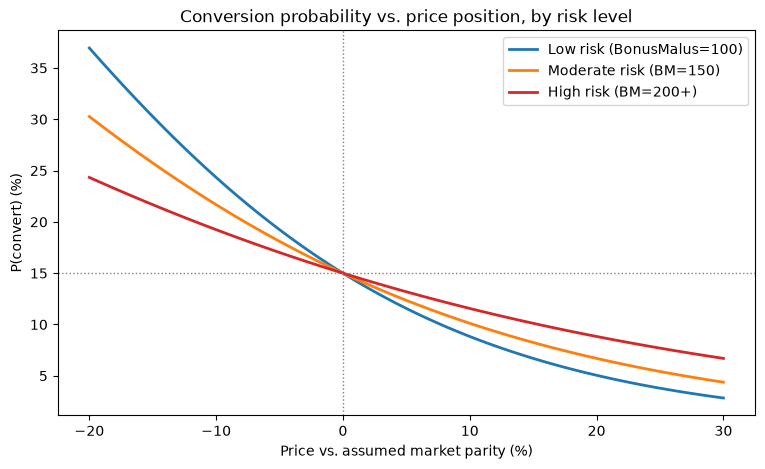

price_vs_market=+0%:  low-risk=15.0%   high-risk=15.0%
price_vs_market=+5%:  low-risk=11.6%   high-risk=13.2%
price_vs_market=+10%:  low-risk=8.8%   high-risk=11.6%
price_vs_market=+15%:  low-risk=6.7%   high-risk=10.1%
price_vs_market=+20%:  low-risk=5.0%   high-risk=8.8%


In [2]:
price_positions = np.linspace(-0.20, 0.30, 100)
fig, ax = plt.subplots(figsize=(9, 5))
for bm, label, color in [(100.0, "Low risk (BonusMalus=100)", "#1f77b4"), (150.0, "Moderate risk (BM=150)", "#ff7f0e"), (RISK_ACCESS_SATURATION_BONUS_MALUS, "High risk (BM=200+)", "#d62728")]:
    probs = conversion_probability(price_positions, pd.Series([bm] * len(price_positions)))
    ax.plot(price_positions * 100, probs * 100, label=label, color=color, linewidth=2)
ax.axhline(BASELINE_CONVERSION_RATE * 100, color="gray", linestyle=":", linewidth=1)
ax.axvline(0, color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("Price vs. assumed market parity (%)")
ax.set_ylabel("P(convert) (%)")
ax.set_title("Conversion probability vs. price position, by risk level")
ax.legend()
plt.show()

for pct in [0.0, 0.05, 0.10, 0.15, 0.20]:
    p_low = conversion_probability(pct, pd.Series([100.0]))[0]
    p_high = conversion_probability(pct, pd.Series([RISK_ACCESS_SATURATION_BONUS_MALUS]))[0]
    print(f"price_vs_market={pct:+.0%}:  low-risk={p_low:.1%}   high-risk={p_high:.1%}")

**Reading: sanity checks the formula should pass, and does:**
- At market parity (0%), every risk level converges to the 15% baseline, as designed.
- A low-risk prospect quoted +10% above market drops to **8.8%** (a 41% relative fall from baseline);
  a high-risk prospect facing the same relative overpricing only falls to **11.6%** (a 23% relative
  fall): the risk-access dampening effect, working as intended.

## 2. New business is more price-elastic than renewal: quantified

The two models use different baselines and different logit-scale elasticities for stated, cited
reasons (Section 1's table), but the practical question a pricing committee actually asks is simpler:
*"if we move price by the same amount, which group reacts more?"* Answered directly here, at a
representative tenure/risk level for each model.

In [3]:
for pct in [0.05, 0.10, 0.15, 0.20]:
    p_conv_parity = conversion_probability(0.0, pd.Series([100.0]))[0]
    p_conv_moved = conversion_probability(pct, pd.Series([100.0]))[0]
    conv_relative_drop = 1 - p_conv_moved / p_conv_parity

    p_ret_parity = renewal_probability(0.0, pd.Series([5.0]))[0]  # a representative mid-tenure customer
    p_ret_moved = renewal_probability(pct, pd.Series([5.0]))[0]
    ret_relative_drop = 1 - p_ret_moved / p_ret_parity

    print(f"price change {pct:+.0%}:  conversion relative drop={conv_relative_drop:.1%}   retention relative drop={ret_relative_drop:.1%}   ratio={conv_relative_drop / ret_relative_drop:.1f}x")

price change +5%:  conversion relative drop=22.9%   retention relative drop=2.0%   ratio=11.4x
price change +10%:  conversion relative drop=41.1%   retention relative drop=4.3%   ratio=9.7x
price change +15%:  conversion relative drop=55.4%   retention relative drop=6.8%   ratio=8.2x
price change +20%:  conversion relative drop=66.4%   retention relative drop=9.5%   ratio=7.0x


**Finding:** at every price level tested, the relative drop in conversion probability is **7x to 11x
larger** than the relative drop in retention probability for the same price move (widest at small price
moves, narrowing somewhat as the move grows). This is not a coincidence of the chosen logit coefficients
alone: it is compounded by conversion's much lower baseline (a logistic curve's absolute sensitivity is
highest near 50%, and a low baseline like 15% sits in a region where even a moderate logit-scale shift
produces a large *relative* swing). Both effects point the same direction as the literature this
notebook cites: **prospects are dramatically more price-sensitive than existing customers**, which is
exactly why insurers price renewals and new business differently in practice: a real, well-grounded
pattern this simulator reproduces quantitatively, even though its specific numbers are assumptions.

## 3. Applying the model to Segment X (`BonusMalus` 51-80)

Same indicated correction as Phase 9 (loaded from Phase 8), so the retention and conversion effects
can be compared directly when Phase 11 combines them.

In [4]:
from src.pricing.segment_x import in_segment_x, load_segment_x

segment_x = load_segment_x(PROJECT_ROOT)  # written by Phase 8: loaded, not retyped
price_change = segment_x["indicated_price_change"]
seg = df[in_segment_x(df, segment_x)].copy()

seg["p_convert_parity"] = conversion_probability(0.0, seg["BonusMalus"])
seg["p_convert_repriced"] = conversion_probability(price_change, seg["BonusMalus"])

mean_p_parity = seg["p_convert_parity"].mean()
mean_p_repriced = seg["p_convert_repriced"].mean()
relative_drop = 1 - mean_p_repriced / mean_p_parity

print(f"Segment X ({segment_x['label']}): {len(seg):,} policies ({seg['Exposure'].sum() / df['Exposure'].sum():.1%} of exposure)")
print(f"Mean P(convert) at assumed market parity : {mean_p_parity:.1%}")
print(f"Mean P(convert) at {price_change:+.0%} above market      : {mean_p_repriced:.1%}")
print(f"Relative drop in conversion probability    : {relative_drop:.1%}")

Segment X (BonusMalus 51-80): 211,105 policies (28.3% of exposure)
Mean P(convert) at assumed market parity : 15.0%
Mean P(convert) at +17% above market      : 6.0%
Relative drop in conversion probability    : 60.1%


**Reading:** a +17% price position above assumed market parity is projected to cut conversion of new
prospects in this segment by about **60%, relative** (15.0% to 6.0%). For the same move, Phase 9
projects about 4.8% of existing policies lapsing: **the conversion channel is much more exposed to a
price correction than the renewal book**, and Phase 11 weighs the two together. This conversion effect
assumes that competitors price the segment like today's tariff; if the market already charges these
risks more, the real drop would be smaller.

## 4. What's saved from this phase

In [5]:
# Same as Phase 9: no fitted parameters to serialize: the model IS the documented, cited
# assumptions in src/prospect/conversion_model.py. Nothing needs to be persisted from this notebook;
# Phase 11 imports the module directly, exactly as it will import Phase 9's.
print("No artifacts to save: src/prospect/conversion_model.py is imported directly by Phase 11.")

No artifacts to save: src/prospect/conversion_model.py is imported directly by Phase 11.


## Phase 10 summary

| Check | Result |
|---|---|
| Baseline conversion rate | 15% (documented, typical price-comparison-channel quote-to-bind rate) |
| Price elasticity | -6.0 (documented, larger than retention's -4.5: new business is more price-sensitive) |
| Segment driver | `BonusMalus`-based risk-access dampening (a new prospect has no tenure): high-risk prospects are less price-sensitive, having fewer alternatives |
| Calibration checks | Converges to baseline at market parity (all risk levels); low-risk prospect at +10% falls 41% relative, high-risk 23% relative |
| **New business vs. renewal elasticity** | Conversion's relative drop is 7x to 11x retention's for the same price move, across the levels tested |
| Segment X application | `BonusMalus` 51-80 at +17%: mean P(convert) 15.0% to 6.0%, a 60% relative drop |
| Empirical anchor considered | Kaggle "Health Insurance Cross Sell Prediction": not used (only unofficial mirrors found, uncertain provenance) |
| Framing | A documented scenario simulator, like Phase 9 |

**Output:** [`src/prospect/conversion_model.py`](../src/prospect/conversion_model.py), ready for
**Phase 11: commercial premium and scenario engine**, which combines this conversion effect with Phase 9's
retention effect and Phase 7's technical premium.